# Finance, Firms and Jobs in Ghana

**Evans K. Owusu, PhD** · World Bank Enterprise Survey, Ghana 2023 (713 formal private establishments)

This notebook asks four questions that matter for designing a private-sector lending operation:

1. **What binds?** Which obstacle do firms rank first?
2. **Where do firms drop out of the credit market?** And why?
3. **Who is excluded?** Small firms, women-led firms, young firms.
4. **Does credit go with job creation?**

All estimates use the survey weights (`wmedian`) and the stratified design (`strata`), with design-based standard errors.

- **Data use:** the firm-level file is covered by the Enterprise Surveys confidentiality agreement. It is not included in this repository. Only aggregate results are shown. Place `Ghana-2023-full-data.dta` in `data/` to run the notebook.

- **Workflow:** I designed the analysis and built it in Python, with Claude (Anthropic) as a coding assistant. The same pipeline exists as a script (`python/analysis.py`) and in R (`R/analysis.R`). `verify_match.py` checks that the versions agree.

In [16]:
import json
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [17]:
## Import data

DATA = Path("~/Desktop/World_Bank/Ghana-2023-full-data.dta").expanduser()
OUT = Path("output")
OUT.mkdir(exist_ok=True)
pd.set_option("display.precision", 3)

In [18]:
print(DATA.exists())

True


## Survey design and estimation

The Enterprise Surveys use a stratified sample (by sector, size and region), so plain averages and textbook standard errors are wrong. The class below gives design-based estimates by Taylor linearisation. It reproduces R's `survey` package with `options(survey.lonely.psu = "adjust")`, since 12 strata contain a single firm.

- **Means and shares** are weighted ratios. Domain estimates (e.g. small firms only) keep the full design, so their standard errors are correct.
- **Regressions** are weighted logit or OLS with a design-based sandwich variance.

(This is the same code as `python/survey.py`.)

In [19]:
from __future__ import annotations
import numpy as np
import pandas as pd
from scipy import stats


class StratifiedDesign:
    def __init__(self, df: pd.DataFrame, weight: str, strata: str):
        self.df = df.reset_index(drop=True)
        self.w = self.df[weight].astype(float).to_numpy()
        self.strata = self.df[strata].to_numpy()
        codes, self._sidx = np.unique(self.strata, return_inverse=True)
        self.n_strata = len(codes)
        self.n_h = np.bincount(self._sidx)                # PSUs per stratum (full sample)
        self.n = len(self.df)
        self.df_resid = self.n - self.n_strata             # design degrees of freedom

    # ---- core variance of a total of influence values ------------------------
    def _var_total(self, z: np.ndarray) -> np.ndarray:
        """Linearised variance of sum(z) under the stratified design.
        z: (n,) or (n, p) array of weighted influence values (0 outside domain)."""
        z = np.atleast_2d(z.T).T if z.ndim == 1 else z
        p = z.shape[1]
        grand = z.mean(axis=0)
        V = np.zeros((p, p))
        sums = np.zeros((self.n_strata, p))
        np.add.at(sums, self._sidx, z)
        means = sums / self.n_h[:, None]
        for h in range(self.n_strata):
            zh = z[self._sidx == h]
            if self.n_h[h] > 1:
                d = zh - means[h]
                V += self.n_h[h] / (self.n_h[h] - 1) * d.T @ d
            else:                                         # lonely PSU: centre on grand mean
                d = zh - grand
                V += d.T @ d
        return V

    # ---- weighted mean (proportion) with 95% CI ---------------------------------
    def mean(self, y: pd.Series | np.ndarray, domain: np.ndarray | None = None) -> dict:
        y = np.asarray(y, dtype=float)
        ok = ~np.isnan(y)
        if domain is not None:
            ok &= np.asarray(domain, dtype=bool)
        w = np.where(ok, self.w, 0.0)
        yv = np.where(ok, y, 0.0)
        W = w.sum()
        est = (w * yv).sum() / W
        z = w * (yv - est) / W
        se = float(np.sqrt(self._var_total(z)[0, 0]))
        q = stats.norm.ppf(0.975)
        return {"est": est, "se": se, "lo": est - q * se, "hi": est + q * se,
                "n": int(ok.sum())}

    def mean_by(self, y, by: pd.Series, domain=None) -> pd.DataFrame:
        rows = []
        for level in sorted(pd.Series(by).dropna().unique()):
            dom = (np.asarray(by) == level)
            if domain is not None:
                dom &= np.asarray(domain, dtype=bool)
            r = self.mean(y, dom)
            r["group"] = level
            rows.append(r)
        return pd.DataFrame(rows)[["group", "est", "se", "lo", "hi", "n"]]

    def shares(self, cat: pd.Series, domain=None) -> pd.DataFrame:
        """Weighted distribution of a categorical variable (like svymean(~factor))."""
        cat = pd.Series(cat).reset_index(drop=True)
        ok = cat.notna().to_numpy().copy()
        if domain is not None:
            ok &= np.asarray(domain, dtype=bool)
        rows = []
        for level in cat[ok].unique():
            ind = np.where(ok, (cat == level).astype(float), np.nan)
            r = self.mean(ind)
            r["category"] = level
            rows.append(r)
        return (pd.DataFrame(rows)[["category", "est", "se", "lo", "hi", "n"]]
                .sort_values("est", ascending=False).reset_index(drop=True))

    # ---- survey-weighted GLM (logit or linear) ---------------------------------
    def glm(self, y: str, X: pd.DataFrame, family: str = "logit") -> pd.DataFrame:
        yv = self.df[y].astype(float).to_numpy()
        Xm = X.astype(float).to_numpy()
        ok = ~np.isnan(yv) & ~np.isnan(Xm).any(axis=1)
        w = np.where(ok, self.w, 0.0)
        yv = np.where(ok, yv, 0.0)
        Xm = np.where(ok[:, None], Xm, 0.0)

        if family == "linear":
            A = Xm.T @ (w[:, None] * Xm)
            beta = np.linalg.solve(A, Xm.T @ (w * yv))
            resid = yv - Xm @ beta
            scores = (w * resid)[:, None] * Xm
        else:                                             # logit via IRLS
            beta = np.zeros(Xm.shape[1])
            for _ in range(100):
                p = 1 / (1 + np.exp(-(Xm @ beta)))
                Wt = w * p * (1 - p)
                A = Xm.T @ (Wt[:, None] * Xm)
                step = np.linalg.solve(A, Xm.T @ (w * (yv - p)))
                beta += step
                if np.max(np.abs(step)) < 1e-10:
                    break
            p = 1 / (1 + np.exp(-(Xm @ beta)))
            A = Xm.T @ ((w * p * (1 - p))[:, None] * Xm)
            scores = (w * (yv - p))[:, None] * Xm

        Ainv = np.linalg.inv(A)
        V = Ainv @ self._var_total(scores) @ Ainv
        se = np.sqrt(np.diag(V))
        dfree = self.df_resid + 1 - Xm.shape[1]
        t = beta / se
        q = stats.t.ppf(0.975, dfree)
        out = pd.DataFrame({"term": X.columns, "estimate": beta, "se": se,
                            "t": t, "p_value": 2 * stats.t.sf(np.abs(t), dfree),
                            "lo": beta - q * se, "hi": beta + q * se})
        if family == "logit":
            out["odds_ratio"] = np.exp(out["estimate"])
            out["or_lo"] = np.exp(out["lo"])
            out["or_hi"] = np.exp(out["hi"])
        out.attrs["n_used"] = int(ok.sum())
        return out


def dummies(s: pd.Series, ref, prefix: str) -> pd.DataFrame:
    """Treatment-coded dummies, NaN-preserving, with `ref` as the omitted level."""
    levels = [l for l in pd.Series(s).dropna().unique() if l != ref]
    levels = sorted(levels, key=lambda v: str(v))
    out = pd.DataFrame({f"{prefix}{l}": (s == l).astype(float) for l in levels})
    out[s.isna().to_numpy()] = np.nan
    return out

## 1. Load and clean the data

WBES codes non-response as negative values (−9 don't know, −7 does not apply, −6 still in process). These are set to missing. Firm size uses permanent full-time employees: small 5–19, medium 20–99, large 100+.

In [20]:
raw = pd.read_stata(DATA, convert_categoricals=False)


def clean(s):
    """WBES codes non-response as negatives (-9 don't know, -7 n/a, -6 in process...)."""
    s = pd.to_numeric(s, errors="coerce").astype(float)
    return s.where(s >= 0)


def yes_no(s):
    s = clean(s)
    return s.map({1: 1.0, 2: 0.0})


df = pd.DataFrame(index=raw.index)
df["wmedian"] = raw["wmedian"].astype(float)
df["strata"] = raw["strata"]
raw.shape

(713, 355)

### Firm characteristics
Sector and region dummies use food & beverages and Greater Accra as reference groups. A *young firm* is 0–5 years old. An *exporter* sells at least 10% of output abroad, directly or indirectly.

In [21]:
# --- Firm characteristics -----------------------------------------------------
l1, l2 = clean(raw["l1"]), clean(raw["l2"])
df["size"] = pd.cut(l1, [0, 19, 99, np.inf], labels=["Small", "Medium", "Large"]).astype(object)
df["size_medium"] = (df["size"] == "Medium").astype(float)
df["size_large"] = (df["size"] == "Large").astype(float)

sector_map = {1: "Food & beverages", 2: "Other manufacturing", 3: "Retail",
              4: "Hotels & restaurants", 5: "Other services"}
df["sector"] = raw["a4a"].map(sector_map)
for code, name in [(2, "othmfg"), (3, "retail"), (4, "hotels"), (5, "othserv")]:
    df[f"sector_{name}"] = (raw["a4a"] == code).astype(float)          # ref: food & bev

region_map = {1: "Greater Accra, Eastern, Volta, Oti", 2: "Ashanti & Bono regions",
              3: "Western & Central regions", 4: "Northern regions"}
df["region"] = raw["a2"].map(region_map)
for code, name in [(2, "ashanti"), (3, "western"), (4, "northern")]:
    df[f"region_{name}"] = (raw["a2"] == code).astype(float)           # ref: Greater Accra

age = raw["a14y"].astype(float) - clean(raw["b5"])
df["firm_age"] = age.where(age >= 0)
df["log_age"] = np.log1p(df["firm_age"])
df["young_firm"] = (df["firm_age"] <= 5).astype(float).where(df["firm_age"].notna())

df["female_mgr"] = yes_no(raw["b7a"])
df["female_own"] = yes_no(raw["b4"])
exp_share = clean(raw["d3b"]).fillna(0) + clean(raw["d3c"]).fillna(0)
df["exporter"] = (exp_share >= 10).astype(float).where(clean(raw["d3b"]).notna() | clean(raw["d3c"]).notna())
df["audited"] = yes_no(raw["k21"])
df["website"] = yes_no(raw["c22b"])
df["innovator"] = ((yes_no(raw["h1"]) == 1) | (yes_no(raw["h5"]) == 1)).astype(float)
df.loc[yes_no(raw["h1"]).isna() & yes_no(raw["h5"]).isna(), "innovator"] = np.nan

### Finance outcomes

- **Needs credit:** applied for a loan or credit line, or didn't apply for any reason other than *"no need, sufficient capital"*.
- **Discouraged:** needs credit but did not apply.
- **Approved:** most recent application approved in full or in part.

In [22]:
# --- Finance outcomes ---------------------------------------------------------
k30 = clean(raw["k30"])
df["finance_major"] = (k30 >= 3).astype(float).where(k30.notna())
m1a = clean(raw["m1a"])
obstacle_map = {1: "Access to finance", 2: "Access to land", 3: "Licensing & permits",
                4: "Corruption", 5: "Courts", 6: "Crime & theft", 7: "Customs & trade",
                8: "Electricity", 9: "Skills shortage", 10: "Labour regulations",
                11: "Political instability", 12: "Informal competitors",
                13: "Tax administration", 14: "Tax rates", 15: "Transport"}
df["biggest_obstacle"] = m1a.map(obstacle_map)

df["has_account"] = yes_no(raw["k6"])
k82 = clean(raw["k82"])
df["has_credit"] = k82.map({1: 1.0, 2: 1.0, 3: 1.0, 4: 0.0})
k162 = clean(raw["k162"])
df["applied"] = k162.map({1: 1.0, 2: 1.0, 3: 1.0, 4: 0.0})
k17 = clean(raw["k17"])
reason_map = {1: "No need (enough capital)", 2: "Complex procedures",
              3: "Unfavourable interest rates", 4: "Collateral too high",
              5: "Loan size/maturity too small", 6: "Did not expect approval", 7: "Other"}
df["reason_not_applying"] = k17.map(reason_map)

# Credit need: applied, or did not apply for a reason other than "no need"
df["needs_credit"] = np.select(
    [df["applied"] == 1, (df["applied"] == 0) & k17.between(2, 7), (df["applied"] == 0) & (k17 == 1)],
    [1.0, 1.0, 0.0], default=np.nan)
df["discouraged"] = np.where(df["needs_credit"] == 1, 1.0 - df["applied"], np.nan)

k20 = clean(raw["k20a1"])
approved = k20.map({1: 1.0, 2: 1.0, 3: 0.0, 4: 0.0})
df["applied_approved"] = np.select(
    [df["applied"] == 0, (df["applied"] == 1) & approved.notna()],
    [0.0, approved], default=np.nan)
df["approved_if_applied"] = np.where(df["applied"] == 1, approved, np.nan)

### Infrastructure and jobs
Employment growth is the annualised mid-point rate over three years, (L₁ − L₀) / ((L₁ + L₀)/2) / 3. It's bounded and defined for firms that started from zero.

In [23]:
# --- Infrastructure -------------------------------------------------------------
df["outages"] = yes_no(raw["c6"])
df["generator"] = yes_no(raw["c10"])

# --- Jobs: annualised employment growth over 3 years (DHS mid-point rate, %) ----
# Bounded, symmetric and defined when a firm grew from zero.
valid = l1.notna() & l2.notna() & ((l1 + l2) > 0)
df["emp_growth"] = np.where(valid, (l1 - l2) / ((l1 + l2) / 2) / 3 * 100, np.nan)
df["base_size_medium"] = np.where(l2.notna(), ((l2 >= 20) & (l2 < 100)).astype(float), np.nan)
df["base_size_large"] = np.where(l2.notna(), (l2 >= 100).astype(float), np.nan)

df.to_csv(OUT / "_analysis_vars_DO_NOT_SHARE.csv", index=False)   # firm-level: keep private

In [24]:
des = StratifiedDesign(df, "wmedian", "strata")
results = {}
print(f"Firms: {des.n}  strata: {des.n_strata}  weighted population: {df.wmedian.sum():,.0f}")

Firms: 713  strata: 104  weighted population: 8,887


## 2. Headline indicators
Weighted shares of all firms, with 95% confidence intervals.

In [25]:
headline_vars = {
    "finance_biggest_obstacle": (df["biggest_obstacle"] == "Access to finance").astype(float).where(df["biggest_obstacle"].notna()),
    "finance_major_obstacle": df["finance_major"],
    "has_account": df["has_account"],
    "needs_credit": df["needs_credit"],
    "applied": df["applied"],
    "applied_and_approved": df["applied_approved"],
    "has_credit": df["has_credit"],
    "discouraged_of_needing": df["discouraged"],
    "approved_if_applied": df["approved_if_applied"],
    "outages": df["outages"],
    "generator": df["generator"],
    "female_top_manager": df["female_mgr"],
    "female_ownership": df["female_own"],
}
head = []
for k, v in headline_vars.items():
    r = des.mean(v)
    head.append({"indicator": k, **r})
    results[f"mean.{k}"] = r["est"]
    results[f"se.{k}"] = r["se"]
head = pd.DataFrame(head)
head.to_csv(OUT / "01_headline_indicators.csv", index=False)
head.round(3)

,indicator,est,se,lo,hi,n
0,finance_biggest_obstacle,0.392,0.029,0.336,0.449,696
1,finance_major_obstacle,0.327,0.023,0.282,0.373,707
2,has_account,0.908,0.016,0.876,0.940,705
3,needs_credit,0.492,0.028,0.438,0.547,695
4,applied,0.136,0.020,0.097,0.175,701
5,applied_and_approved,0.117,0.019,0.080,0.154,697
6,has_credit,0.219,0.024,0.172,0.266,696
7,discouraged_of_needing,0.722,0.039,0.647,0.798,339
8,approved_if_applied,0.901,0.050,0.802,1.000,95
9,outages,0.738,0.023,0.693,0.782,710


## Chart style
One highlight colour per chart, with everything else in grey and values labelled directly.

In [26]:
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#c9c8c2"
INK, INK2 = "#0b0b0b", "#52514e"
SRC = "Source: World Bank Enterprise Survey, Ghana 2023 (n = 713). Weighted estimates; author's calculations."
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10, "axes.edgecolor": GREY,
                     "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK,
                     "axes.spines.top": False, "axes.spines.right": False})


def finish(fig, ax, title, subtitle, path):
    fig.text(0.01, 0.97, title, fontsize=13, fontweight="bold", color=INK, va="top")
    fig.text(0.01, 0.905, subtitle, fontsize=9.5, color=INK2, va="top")
    fig.text(0.01, 0.015, SRC, fontsize=7.5, color=INK2)
    fig.savefig(path, dpi=300, facecolor="white")
    plt.show()


def hbar(ax, labels, values, colors, err=None):
    y = np.arange(len(labels))[::-1]
    ax.barh(y, values, color=colors, height=0.62, xerr=err,
            error_kw={"ecolor": INK2, "elinewidth": 0.8, "capsize": 0})
    ax.set_yticks(y, labels)
    ax.tick_params(axis="y", length=0)
    ax.spines["left"].set_visible(False)
    ax.xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1, decimals=0))
    ax.grid(axis="x", color="#ecebe7", lw=0.6)
    ax.set_axisbelow(True)
    return y

## 3. What binds? The biggest obstacle

In [27]:
obs = des.shares(df["biggest_obstacle"])
obs.to_csv(OUT / "02_biggest_obstacle.csv", index=False)
for _, r in obs.iterrows():
    results[f"obstacle.{r['category']}"] = r["est"]
fin_top = headline_vars["finance_biggest_obstacle"]
by_size_top = des.mean_by(fin_top, df["size"])
by_size_top.to_csv(OUT / "02b_finance_top_by_size.csv", index=False)
obs.head(8).round(3)

,category,est,se,lo,hi,n
0,Access to finance,0.392,0.029,0.336,0.449,696
1,Tax rates,0.246,0.026,0.196,0.296,696
2,Electricity,0.065,0.014,0.038,0.092,696
3,Corruption,0.055,0.015,0.025,0.085,696
4,Political instability,0.054,0.015,0.025,0.082,696
5,Informal competitors,0.049,0.014,0.020,0.077,696
6,Access to land,0.029,0.009,0.011,0.047,696
7,Tax administration,0.024,0.008,0.007,0.040,696


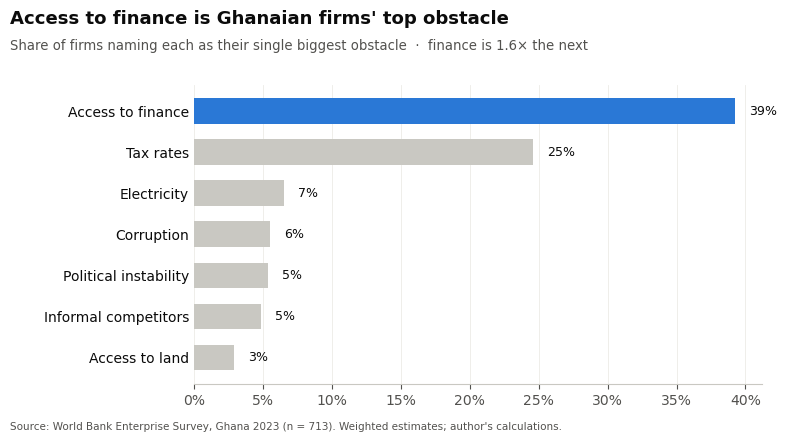

In [28]:
# Fig 1 - biggest obstacle
top = obs.head(7)
fig, ax = plt.subplots(figsize=(8, 4.4))
fig.subplots_adjust(left=0.24, right=0.95, top=0.80, bottom=0.12)
cols = [BLUE if c == "Access to finance" else GREY for c in top["category"]]
y = hbar(ax, top["category"], top["est"], cols)
for yi, v in zip(y, top["est"]):
    ax.text(v + 0.01, yi, f"{v:.0%}", va="center", fontsize=9, color=INK)
finish(fig, ax, "Access to finance is Ghanaian firms' top obstacle",
       f"Share of firms naming each as their single biggest obstacle  ·  finance is {obs.iloc[0]['est']/obs.iloc[1]['est']:.1f}× the next",
       OUT / "fig1_biggest_obstacle.png")

Access to finance leads clearly, ahead of tax rates. Electricity comes a distant third, even though about three-quarters of firms had outages. Most of them cope with generators.

## 4. The credit funnel: where firms drop out, and why

In [29]:
funnel = pd.DataFrame([
    {"stage": "All firms", "est": 1.0},
    {"stage": "Have a bank account", "est": results["mean.has_account"]},
    {"stage": "Need external credit", "est": results["mean.needs_credit"]},
    {"stage": "Applied for credit", "est": results["mean.applied"]},
    {"stage": "Approved (full or part)", "est": results["mean.applied_and_approved"]},
])
funnel.to_csv(OUT / "03_credit_funnel.csv", index=False)

reasons_disc = des.shares(df["reason_not_applying"], domain=(df["discouraged"] == 1).to_numpy())
reasons_disc.to_csv(OUT / "04_reasons_discouraged.csv", index=False)
reasons_all = des.shares(df["reason_not_applying"], domain=(df["applied"] == 0).to_numpy())
reasons_all.to_csv(OUT / "04b_reasons_all_nonapplicants.csv", index=False)
for _, r in reasons_disc.iterrows():
    results[f"reason_disc.{r['category']}"] = r["est"]
funnel

,stage,est
0,All firms,1.000
1,Have a bank account,0.908
2,Need external credit,0.492
3,Applied for credit,0.136
4,Approved (full or part),0.117


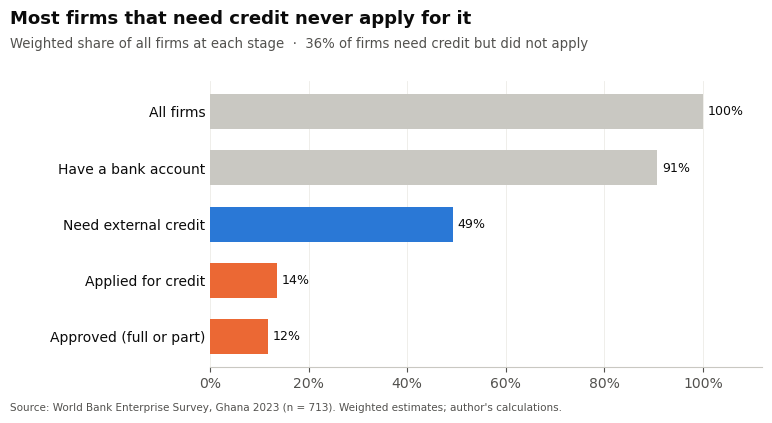

In [30]:
# Fig 2 - credit funnel
fig, ax = plt.subplots(figsize=(8, 4.2))
fig.subplots_adjust(left=0.26, right=0.95, top=0.80, bottom=0.12)
cols = [GREY, GREY, BLUE, ORANGE, ORANGE]
y = hbar(ax, funnel["stage"], funnel["est"], cols)
ax.set_xlim(0, 1.12)
for yi, v in zip(y, funnel["est"]):
    ax.text(v + 0.01, yi, f"{v:.0%}", va="center", fontsize=9, color=INK)
gap = results["mean.needs_credit"] - results["mean.applied"]
finish(fig, ax, "Most firms that need credit never apply for it",
       f"Weighted share of all firms at each stage  ·  {gap:.0%} of firms need credit but did not apply",
       OUT / "fig2_credit_funnel.png")

In [31]:
reasons_disc.round(3)

,category,est,se,lo,hi,n
0,Unfavourable interest rates,0.641,0.048,0.546,0.736,240
1,Other,0.113,0.031,0.051,0.174,240
2,Complex procedures,0.110,0.031,0.049,0.170,240
3,Collateral too high,0.084,0.026,0.032,0.135,240
4,Loan size/maturity too small,0.042,0.025,-0.007,0.091,240
5,Did not expect approval,0.011,0.005,0.001,0.021,240


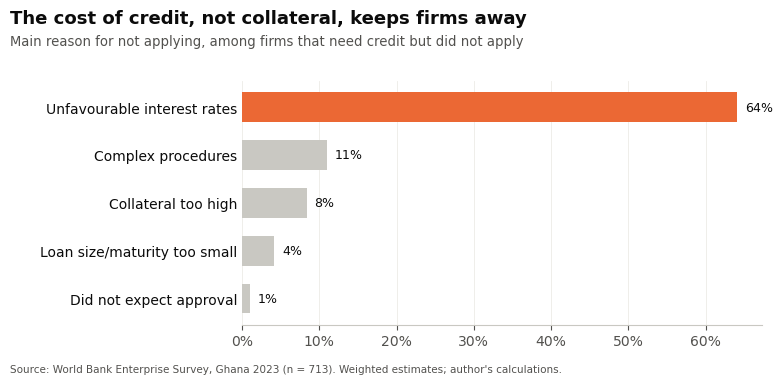

In [32]:
# Fig 3 - reasons among discouraged borrowers
rd = reasons_disc[reasons_disc["category"] != "Other"]
fig, ax = plt.subplots(figsize=(8, 3.8))
fig.subplots_adjust(left=0.30, right=0.95, top=0.78, bottom=0.14)
cols = [ORANGE if c == "Unfavourable interest rates" else GREY for c in rd["category"]]
y = hbar(ax, rd["category"], rd["est"], cols)
for yi, v in zip(y, rd["est"]):
    ax.text(v + 0.01, yi, f"{v:.0%}", va="center", fontsize=9, color=INK)
finish(fig, ax, "The cost of credit, not collateral, keeps firms away",
       "Main reason for not applying, among firms that need credit but did not apply",
       OUT / "fig3_reasons_discouraged.png")

**This is the key result.** Firms that apply are almost always approved, so the funnel narrows *before* the application. Among firms that need credit but stay away, unfavourable interest rates dominate and collateral is a minor reason.

For a lending operation, this points toward instruments that lower the *price* of SME credit, rather than collateral-focused guarantees alone. One caveat: fieldwork overlapped with Ghana's 2022–23 macroeconomic crisis, so part of this may be cyclical.

## 5. Who is excluded? Firm size, gender and firm age

In [33]:
groupings = {
    "Firm size": df["size"],
    "Top manager": df["female_mgr"].map({1.0: "Female", 0.0: "Male"}),
    "Ownership": df["female_own"].map({1.0: "Any female owner", 0.0: "No female owner"}),
    "Firm age": df["young_firm"].map({1.0: "Young (0-5 yrs)", 0.0: "Established (6+ yrs)"}),
}
gap_rows = []
for outcome in ["has_credit", "discouraged", "finance_major", "applied"]:
    for gname, g in groupings.items():
        t = des.mean_by(df[outcome], g)
        t.insert(0, "dimension", gname)
        t.insert(0, "outcome", outcome)
        gap_rows.append(t)
        for _, r in t.iterrows():
            results[f"by.{outcome}.{gname}.{r['group']}"] = r["est"]
gaps = pd.concat(gap_rows, ignore_index=True)
gaps.to_csv(OUT / "05_gaps_by_group.csv", index=False)

(gaps[gaps.outcome.isin(["has_credit", "discouraged"])]
 .pivot_table(index=["dimension", "group"], columns="outcome", values="est")
 .round(3))

outcome                           discouraged  has_credit
dimension   group                                        
Firm age    Established (6+ yrs)        0.715       0.238
            Young (0-5 yrs)             0.744       0.165
Firm size   Large                       0.336       0.410
            Medium                      0.797       0.283
            Small                       0.729       0.178
Ownership   Any female owner            0.681       0.217
            No female owner             0.750       0.219
Top manager Female                      0.626       0.195
            Male                        0.745       0.224

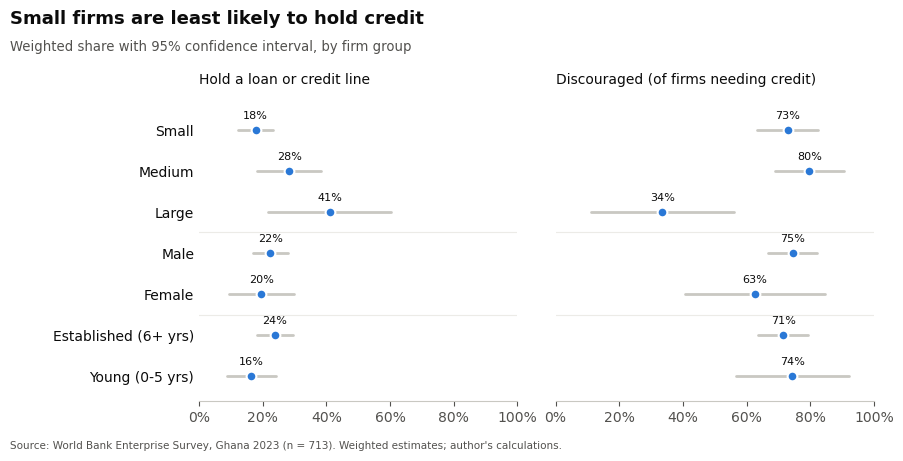

In [34]:
# Fig 4 - who is excluded (dot + CI, two outcomes side by side)
order = [("Firm size", "Small"), ("Firm size", "Medium"), ("Firm size", "Large"),
         ("Top manager", "Male"), ("Top manager", "Female"),
         ("Firm age", "Established (6+ yrs)"), ("Firm age", "Young (0-5 yrs)")]
fig, axes = plt.subplots(1, 2, figsize=(9, 4.6), sharey=True)
fig.subplots_adjust(left=0.22, right=0.97, top=0.78, bottom=0.12, wspace=0.12)
for ax, outcome, title in [(axes[0], "has_credit", "Hold a loan or credit line"),
                           (axes[1], "discouraged", "Discouraged (of firms needing credit)")]:
    sub = gaps[gaps.outcome == outcome].set_index(["dimension", "group"])
    yy = np.arange(len(order))[::-1]
    for yi, key in zip(yy, order):
        r = sub.loc[key]
        ax.plot([r["lo"], r["hi"]], [yi, yi], color=GREY, lw=2, solid_capstyle="round")
        ax.plot(r["est"], yi, "o", color=BLUE, ms=7, mec="white", mew=1.5)
        ax.text(r["est"], yi + 0.28, f"{r['est']:.0%}", ha="center", fontsize=8, color=INK)
    for b in [3.5, 1.5]:
        ax.axhline(b, color="#ecebe7", lw=0.8)
    ax.set_ylim(-0.6, len(order) - 0.2)
    ax.set_yticks(yy, [k[1] for k in order])
    ax.tick_params(axis="y", length=0)
    ax.spines["left"].set_visible(False)
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1, decimals=0))
    ax.set_title(title, fontsize=10, color=INK, loc="left", pad=10)
finish(fig, axes[0], "Small firms are least likely to hold credit",
       "Weighted share with 95% confidence interval, by firm group",
       OUT / "fig4_who_is_excluded.png")

Size is the clear divide: small firms are much less likely to hold credit than large firms. Differences by manager gender and firm age are small, and their confidence intervals overlap.

## 6. Models: what predicts credit, and does credit go with job growth?

**M1** is a survey-weighted logit for holding a loan or credit line. **M2** is survey-weighted OLS for annual employment growth, with baseline size taken from employment three years ago. Both include sector and region fixed effects.

In [35]:
const = pd.Series(1.0, index=df.index, name="(Intercept)")
fe = ["sector_othmfg", "sector_retail", "sector_hotels", "sector_othserv",
      "region_ashanti", "region_western", "region_northern"]

# M1: what predicts holding a loan or credit line?  (PART 5: capabilities)
x1 = ["size_medium", "size_large"] + fe + ["female_mgr", "young_firm", "exporter",
                                           "audited", "website", "innovator"]
X1 = pd.concat([const, df[x1]], axis=1)
m1 = des.glm("has_credit", X1, family="logit")
m1.to_csv(OUT / "06_model_has_credit_logit.csv", index=False)
print("\nM1 has_credit logit (n=%d)\n" % m1.attrs["n_used"],
      m1[["term", "odds_ratio", "or_lo", "or_hi", "p_value"]].round(3).to_string(index=False))

# M2: is credit associated with faster job growth?  (PART 3: jobs)
x2 = ["has_credit", "base_size_medium", "base_size_large"] + fe + ["female_mgr", "exporter", "log_age"]
X2 = pd.concat([const, df[x2]], axis=1)
m2 = des.glm("emp_growth", X2, family="linear")
m2.to_csv(OUT / "07_model_emp_growth_ols.csv", index=False)
print("\nM2 employment growth OLS (n=%d)\n" % m2.attrs["n_used"],
      m2[["term", "estimate", "lo", "hi", "p_value"]].round(3).to_string(index=False))

emp_by_credit = des.mean_by(df["emp_growth"], df["has_credit"].map({1.0: "Has loan/credit line", 0.0: "No loan/credit line"}))
emp_by_credit.to_csv(OUT / "07b_emp_growth_by_credit.csv", index=False)
results["mean.emp_growth"] = des.mean(df["emp_growth"])["est"]
for _, r in emp_by_credit.iterrows():
    results[f"emp_growth.{r['group']}"] = r["est"]

for name, m in [("m1", m1), ("m2", m2)]:
    for _, r in m.iterrows():
        results[f"{name}.coef.{r['term']}"] = r["estimate"]
        results[f"{name}.se.{r['term']}"] = r["se"]
    results[f"{name}.n"] = m.attrs["n_used"]

_ = (OUT / "results_python.json").write_text(json.dumps(results, indent=2, default=float))


M1 has_credit logit (n=675)
            term  odds_ratio  or_lo  or_hi  p_value
    (Intercept)       0.229  0.087  0.607    0.003
    size_medium       1.900  0.978  3.690    0.058
     size_large       3.579  1.323  9.680    0.012
  sector_othmfg       0.400  0.170  0.939    0.035
  sector_retail       0.818  0.339  1.970    0.653
  sector_hotels       0.091  0.032  0.259    0.000
 sector_othserv       0.690  0.300  1.587    0.382
 region_ashanti       2.471  1.208  5.058    0.013
 region_western       0.315  0.153  0.647    0.002
region_northern       1.571  0.726  3.401    0.251
     female_mgr       0.894  0.404  1.976    0.781
     young_firm       0.593  0.296  1.187    0.139
       exporter       0.843  0.408  1.738    0.642
        audited       1.317  0.697  2.489    0.395
        website       1.130  0.592  2.157    0.710
      innovator       1.777  0.920  3.432    0.087

M2 employment growth OLS (n=568)
             term  estimate      lo     hi  p_value
     (Intercept) 

In [36]:
m1[["term", "odds_ratio", "or_lo", "or_hi", "p_value"]].round(3)

,term,odds_ratio,or_lo,or_hi,p_value
0,(Intercept),0.229,0.087,0.607,0.003
1,size_medium,1.900,0.978,3.690,0.058
2,size_large,3.579,1.323,9.680,0.012
3,sector_othmfg,0.400,0.170,0.939,0.035
4,sector_retail,0.818,0.339,1.970,0.653
5,sector_hotels,0.091,0.032,0.259,0.000
6,sector_othserv,0.690,0.300,1.587,0.382
7,region_ashanti,2.471,1.208,5.058,0.013
8,region_western,0.315,0.153,0.647,0.002
9,region_northern,1.571,0.726,3.401,0.251


In [37]:
m2[["term", "estimate", "lo", "hi", "p_value"]].round(3)

,term,estimate,lo,hi,p_value
0,(Intercept),11.584,0.240,22.928,0.045
1,has_credit,1.739,-2.861,6.340,0.458
2,base_size_medium,-7.792,-12.947,-2.636,0.003
3,base_size_large,-9.358,-13.023,-5.692,0.000
4,sector_othmfg,-5.891,-11.951,0.168,0.057
5,sector_retail,-4.789,-11.685,2.107,0.173
6,sector_hotels,-1.019,-8.648,6.610,0.793
7,sector_othserv,0.253,-5.906,6.413,0.936
8,region_ashanti,16.181,7.789,24.574,0.000
9,region_western,3.830,-1.075,8.734,0.126


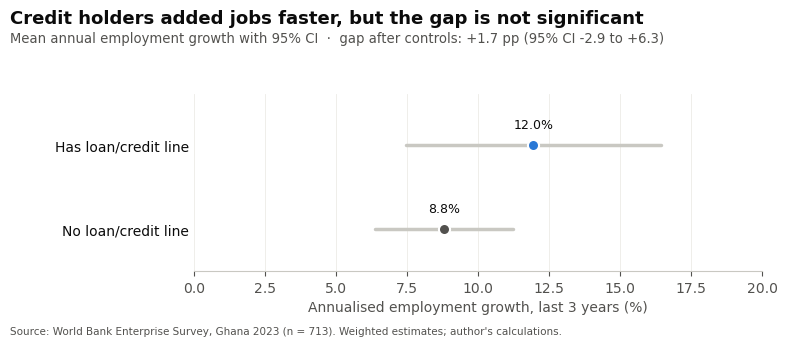

In [38]:
# Fig 5 - credit and jobs (dot + 95% CI)
fig, ax = plt.subplots(figsize=(8, 3.4))
fig.subplots_adjust(left=0.24, right=0.95, top=0.72, bottom=0.20)
e = emp_by_credit.set_index("group").loc[["Has loan/credit line", "No loan/credit line"]]
yy = np.array([1, 0])
for yi, (g, r) in zip(yy, e.iterrows()):
    ax.plot([r["lo"], r["hi"]], [yi, yi], color=GREY, lw=2.5, solid_capstyle="round")
    ax.plot(r["est"], yi, "o", color=BLUE if yi == 1 else INK2, ms=8, mec="white", mew=1.5)
    ax.text(r["est"], yi + 0.2, f"{r['est']:.1f}%", ha="center", fontsize=9, color=INK)
ax.set_yticks(yy, e.index)
ax.set_ylim(-0.5, 1.6)
ax.set_xlim(0, 20)
ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
ax.set_xlabel("Annualised employment growth, last 3 years (%)")
ax.grid(axis="x", color="#ecebe7", lw=0.6)
ax.set_axisbelow(True)
b = m2.set_index("term").loc["has_credit"]
finish(fig, ax, "Credit holders added jobs faster, but the gap is not significant",
       f"Mean annual employment growth with 95% CI  ·  gap after controls: {b['estimate']:+.1f} pp (95% CI {b['lo']:.1f} to {b['hi']:+.1f})",
       OUT / "fig5_credit_and_jobs.png")

After controls, firm size remains the strongest predictor of holding credit. Firms with credit grew employment somewhat faster, but **the gap is not statistically significant**, and the design can't separate cause from selection.

A credible jobs estimate would need an impact evaluation, for example a randomised or phased rollout of an SME credit line.

## Summary

| Question | Answer |
|---|---|
| What binds? | Access to finance, the top obstacle for 39% of firms |
| Where do firms drop out? | Before applying: about half need credit, 14% apply, ~90% of applicants are approved |
| Why? | Cost of credit: 64% of discouraged firms cite interest rates, 8% cite collateral |
| Who is excluded? | Small firms (18% hold credit vs 41% of large firms); no significant gender gap among formal firms |
| Credit and jobs? | Positive but not significant association; needs causal evidence |

**Next steps:** compare with Nigeria and CEMAC Enterprise Surveys, track changes since Ghana 2013, and add trade data for exporters.